# ***Importing Libraries***

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score, normalized_mutual_info_score
import warnings
warnings.filterwarnings('ignore')

SEED = 42

# ***Exploratory Data Analysis (EDA)***

In [2]:
digits = load_digits()
X = digits.data
y = digits.target
images = digits.images

df = pd.DataFrame(X, columns=digits.feature_names)
df.head()

,pixel_0_0,pixel_0_1,pixel_0_2,pixel_0_3,pixel_0_4,pixel_0_5,pixel_0_6,pixel_0_7,pixel_1_0,pixel_1_1,...,pixel_6_6,pixel_6_7,pixel_7_0,pixel_7_1,pixel_7_2,pixel_7_3,pixel_7_4,pixel_7_5,pixel_7_6,pixel_7_7
0,0.0,0.0,5.0,13.0,9.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,6.0,13.0,10.0,0.0,0.0,0.0
1,0.0,0.0,0.0,12.0,13.0,5.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,11.0,16.0,10.0,0.0,0.0
2,0.0,0.0,0.0,4.0,15.0,12.0,0.0,0.0,0.0,0.0,...,5.0,0.0,0.0,0.0,0.0,3.0,11.0,16.0,9.0,0.0
3,0.0,0.0,7.0,15.0,13.0,1.0,0.0,0.0,0.0,8.0,...,9.0,0.0,0.0,0.0,7.0,13.0,13.0,9.0,0.0,0.0
4,0.0,0.0,0.0,1.0,11.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,2.0,16.0,4.0,0.0,0.0


In [3]:
df.tail()

,pixel_0_0,pixel_0_1,pixel_0_2,pixel_0_3,pixel_0_4,pixel_0_5,pixel_0_6,pixel_0_7,pixel_1_0,pixel_1_1,...,pixel_6_6,pixel_6_7,pixel_7_0,pixel_7_1,pixel_7_2,pixel_7_3,pixel_7_4,pixel_7_5,pixel_7_6,pixel_7_7
1792,0.0,0.0,4.0,10.0,13.0,6.0,0.0,0.0,0.0,1.0,...,4.0,0.0,0.0,0.0,2.0,14.0,15.0,9.0,0.0,0.0
1793,0.0,0.0,6.0,16.0,13.0,11.0,1.0,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,6.0,16.0,14.0,6.0,0.0,0.0
1794,0.0,0.0,1.0,11.0,15.0,1.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,2.0,9.0,13.0,6.0,0.0,0.0
1795,0.0,0.0,2.0,10.0,7.0,0.0,0.0,0.0,0.0,0.0,...,2.0,0.0,0.0,0.0,5.0,12.0,16.0,12.0,0.0,0.0
1796,0.0,0.0,10.0,14.0,8.0,1.0,0.0,0.0,0.0,2.0,...,8.0,0.0,0.0,1.0,8.0,12.0,14.0,12.0,1.0,0.0


In [4]:
df.shape

(1797, 64)

In [5]:
images.shape

(1797, 8, 8)

In [6]:
print(df.min().min(), df.max().max())

0.0 16.0


In [7]:
df.describe()

,pixel_0_0,pixel_0_1,pixel_0_2,pixel_0_3,pixel_0_4,pixel_0_5,pixel_0_6,pixel_0_7,pixel_1_0,pixel_1_1,...,pixel_6_6,pixel_6_7,pixel_7_0,pixel_7_1,pixel_7_2,pixel_7_3,pixel_7_4,pixel_7_5,pixel_7_6,pixel_7_7
count,1797.0,1797.000000,1797.000000,1797.000000,1797.000000,1797.000000,1797.000000,1797.000000,1797.000000,1797.000000,...,1797.000000,1797.000000,1797.000000,1797.000000,1797.000000,1797.000000,1797.000000,1797.000000,1797.000000,1797.000000
mean,0.0,0.303840,5.204786,11.835838,11.848080,5.781859,1.362270,0.129661,0.005565,1.993879,...,3.725097,0.206455,0.000556,0.279354,5.557596,12.089037,11.809126,6.764051,2.067891,0.364496
std,0.0,0.907192,4.754826,4.248842,4.287388,5.666418,3.325775,1.037383,0.094222,3.196160,...,4.919406,0.984401,0.023590,0.934302,5.103019,4.374694,4.933947,5.900623,4.090548,1.860122
min,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.0,0.000000,1.000000,10.000000,10.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,1.000000,11.000000,10.000000,0.000000,0.000000,0.000000
50%,0.0,0.000000,4.000000,13.000000,13.000000,4.000000,0.000000,0.000000,0.000000,0.000000,...,1.000000,0.000000,0.000000,0.000000,4.000000,13.000000,14.000000,6.000000,0.000000,0.000000
75%,0.0,0.000000,9.000000,15.000000,15.000000,11.000000,0.000000,0.000000,0.000000,3.000000,...,7.000000,0.000000,0.000000,0.000000,10.000000,16.000000,16.000000,12.000000,2.000000,0.000000
max,0.0,8.000000,16.000000,16.000000,16.000000,16.000000,16.000000,15.000000,2.000000,16.000000,...,16.000000,13.000000,1.000000,9.000000,16.000000,16.000000,16.000000,16.000000,16.000000,16.000000


In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.isnull().sum().sum()

np.int64(0)

In [10]:
pd.Series(y).value_counts().sort_index()

,count
0,178
1,182
2,177
3,183
4,181
5,182
6,181
7,179
8,174
9,180


# ***Data Visualization***

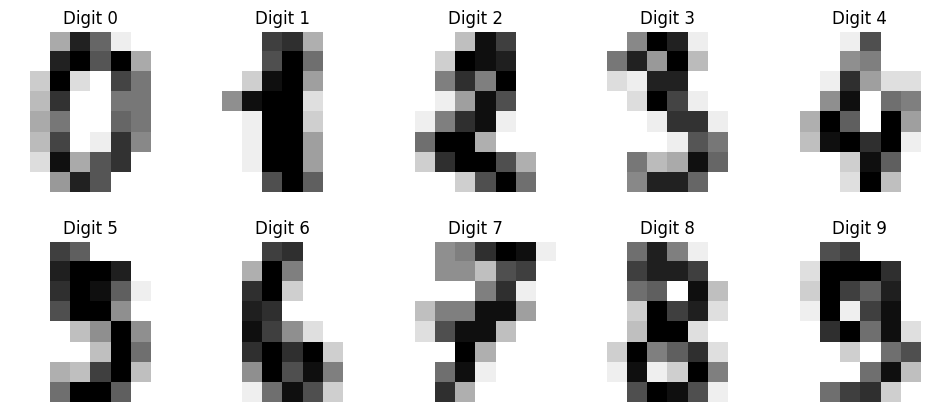

In [11]:
plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(images[i], cmap='gray_r')
    plt.title(f'Digit {y[i]}')
    plt.axis('off')
plt.show()

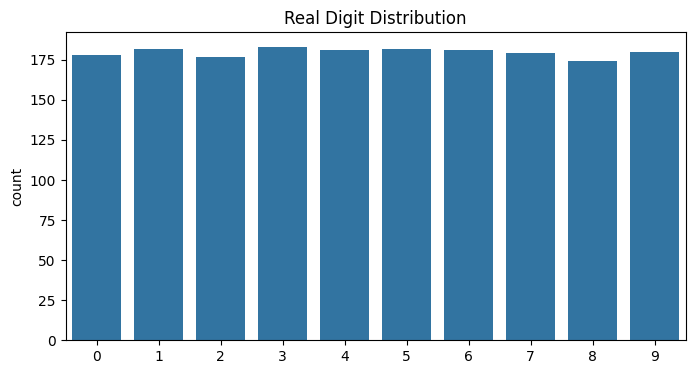

In [12]:
plt.figure(figsize=(8, 4))
sns.countplot(x=y)
plt.title('Real Digit Distribution')
plt.show()

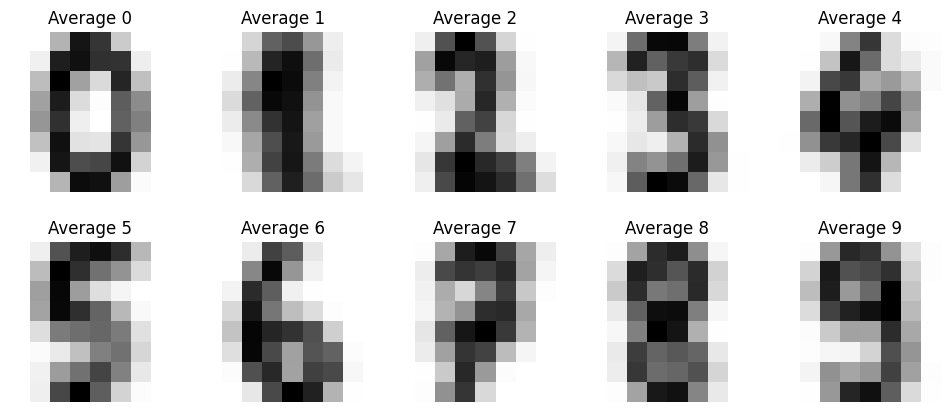

In [13]:
plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(images[y == i].mean(axis=0), cmap='gray_r')
    plt.title(f'Average {i}')
    plt.axis('off')
plt.show()

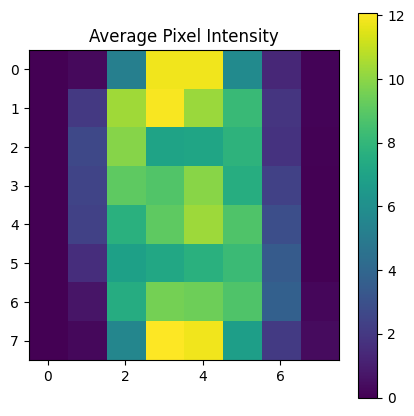

In [14]:
plt.figure(figsize=(5, 5))
plt.imshow(X.mean(axis=0).reshape(8, 8), cmap='viridis')
plt.colorbar()
plt.title('Average Pixel Intensity')
plt.show()

# ***Data Preprocessing***

In [15]:
X_scaled = X / 16.0
X_scaled.shape

(1797, 64)

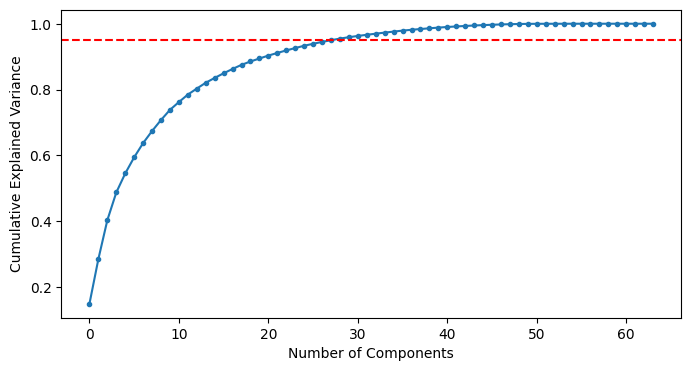

In [16]:
pca_full = PCA(random_state=SEED).fit(X_scaled)

plt.figure(figsize=(8, 4))
plt.plot(np.cumsum(pca_full.explained_variance_ratio_), marker='o', markersize=3)
plt.axhline(0.95, color='r', linestyle='--')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.show()

In [17]:
pca = PCA(n_components=0.95, random_state=SEED)
X_pca = pca.fit_transform(X_scaled)
X_pca.shape

(1797, 29)

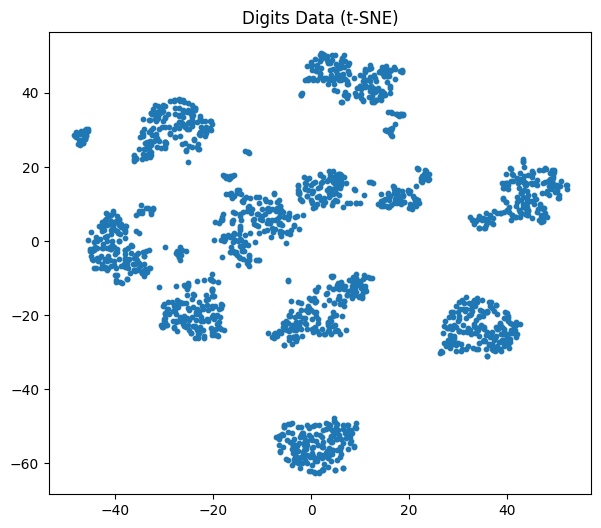

In [18]:
X_tsne = TSNE(n_components=2, random_state=SEED).fit_transform(X_pca)

plt.figure(figsize=(7, 6))
plt.scatter(X_tsne[:, 0], X_tsne[:, 1], s=10)
plt.title('Digits Data (t-SNE)')
plt.show()

# ***Finding the Best K***

In [19]:
results = []
for k in range(2, 16):
    model = KMeans(n_clusters=k, random_state=SEED, n_init=10)
    labels = model.fit_predict(X_pca)
    results.append({
        "K": k,
        "Inertia": model.inertia_,
        "Silhouette": silhouette_score(X_pca, labels)
    })

k_results = pd.DataFrame(results)
k_results

,K,Inertia,Silhouette
0,2,7097.955802,0.124608
1,3,6377.881881,0.133142
2,4,5907.996570,0.135579
3,5,5476.092067,0.144820
4,6,5108.846234,0.161872
5,7,4840.945920,0.170198
6,8,4563.949520,0.190392
7,9,4319.408157,0.201609
8,10,4175.617484,0.194752
9,11,4047.937880,0.195687


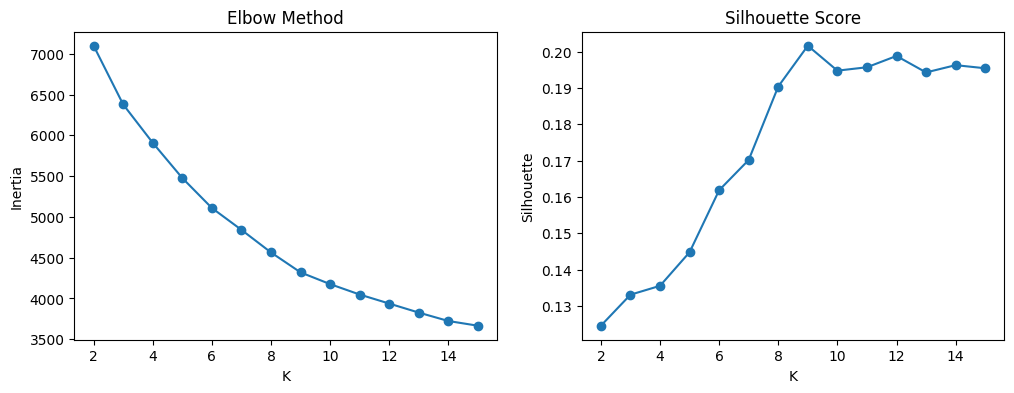

In [20]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(k_results['K'], k_results['Inertia'], marker='o')
plt.title('Elbow Method')
plt.xlabel('K')
plt.ylabel('Inertia')

plt.subplot(1, 2, 2)
plt.plot(k_results['K'], k_results['Silhouette'], marker='o')
plt.title('Silhouette Score')
plt.xlabel('K')
plt.ylabel('Silhouette')

plt.show()

# ***KMeans Model***

In [21]:
kmeans = KMeans(n_clusters=10, random_state=SEED, n_init=10)
kmeans_labels = kmeans.fit_predict(X_pca)
pd.Series(kmeans_labels).value_counts().sort_index()

,count
0,96
1,158
2,182
3,222
4,198
5,174
6,179
7,243
8,164
9,181


# ***Gaussian Mixture Model***

In [22]:
gmm = GaussianMixture(n_components=10, covariance_type='full', random_state=SEED)
gmm_labels = gmm.fit_predict(X_pca)
pd.Series(gmm_labels).value_counts().sort_index()

,count
0,95
1,140
2,176
3,245
4,193
5,183
6,178
7,245
8,173
9,169


# ***Hierarchical Clustering Model***

In [23]:
agg = AgglomerativeClustering(n_clusters=10, linkage='ward')
agg_labels = agg.fit_predict(X_pca)
pd.Series(agg_labels).value_counts().sort_index()

,count
0,182
1,324
2,157
3,191
4,207
5,178
6,181
7,178
8,63
9,136


# ***Evaluating the Clusters***

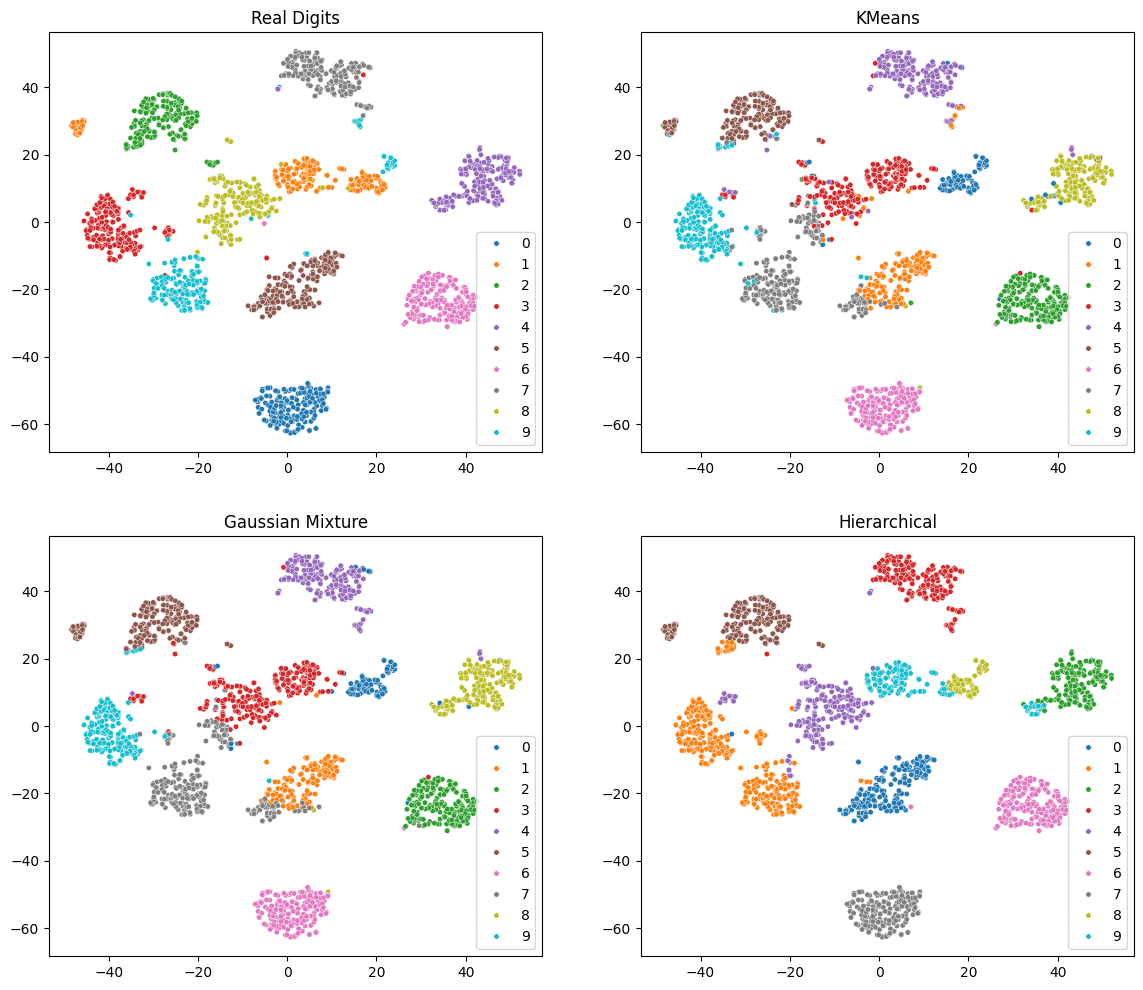

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1], hue=y, palette='tab10', s=15, ax=axes[0, 0])
axes[0, 0].set_title('Real Digits')

sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1], hue=kmeans_labels, palette='tab10', s=15, ax=axes[0, 1])
axes[0, 1].set_title('KMeans')

sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1], hue=gmm_labels, palette='tab10', s=15, ax=axes[1, 0])
axes[1, 0].set_title('Gaussian Mixture')

sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1], hue=agg_labels, palette='tab10', s=15, ax=axes[1, 1])
axes[1, 1].set_title('Hierarchical')

plt.show()

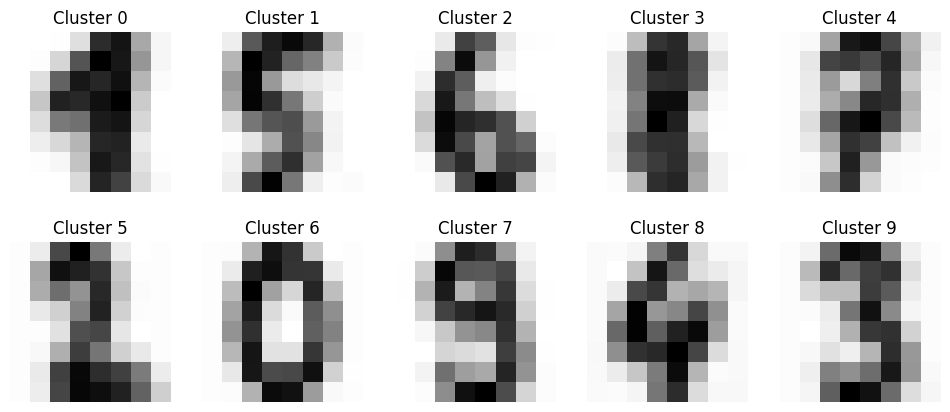

In [25]:
centers = pca.inverse_transform(kmeans.cluster_centers_)

plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(centers[i].reshape(8, 8), cmap='gray_r')
    plt.title(f'Cluster {i}')
    plt.axis('off')
plt.show()

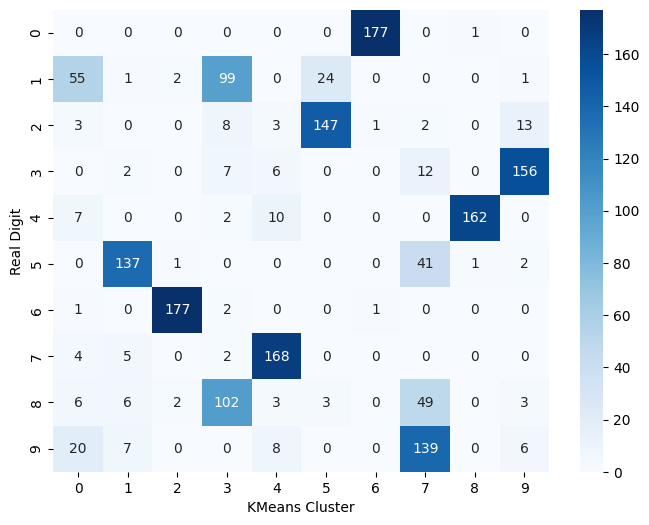

In [26]:
plt.figure(figsize=(8, 6))
sns.heatmap(pd.crosstab(y, kmeans_labels), annot=True, fmt='d', cmap='Blues')
plt.xlabel('KMeans Cluster')
plt.ylabel('Real Digit')
plt.show()

# ***Model Comparison***

In [27]:
results = []
for name, labels in [("KMeans", kmeans_labels), ("Gaussian Mixture", gmm_labels), ("Hierarchical", agg_labels)]:
    results.append({
        "Model": name,
        "Silhouette": silhouette_score(X_pca, labels),
        "Davies-Bouldin": davies_bouldin_score(X_pca, labels),
        "Calinski-Harabasz": calinski_harabasz_score(X_pca, labels),
        "ARI (vs digits)": adjusted_rand_score(y, labels),
        "NMI (vs digits)": normalized_mutual_info_score(y, labels)
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(by="ARI (vs digits)", ascending=False)
results_df.reset_index(drop=True, inplace=True)
results_df

,Model,Silhouette,Davies-Bouldin,Calinski-Harabasz,ARI (vs digits),NMI (vs digits)
0,Hierarchical,0.191824,1.850003,172.812857,0.743381,0.828133
1,Gaussian Mixture,0.188825,1.900704,178.825520,0.696451,0.781606
2,KMeans,0.194752,1.840385,184.354143,0.662459,0.737651


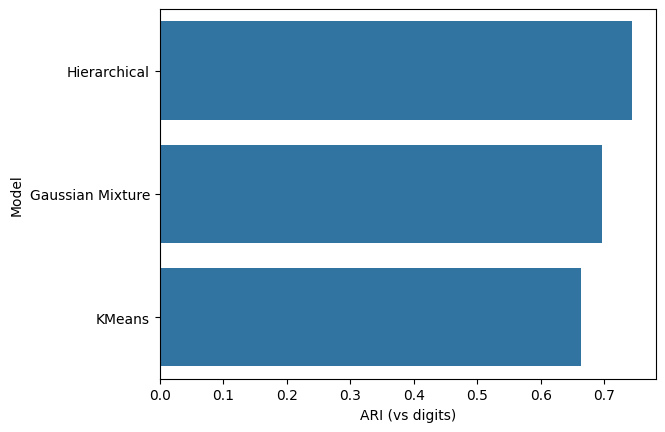

In [28]:
sns.barplot(x="ARI (vs digits)", y="Model", data=results_df)
plt.show()